# Mixing experiment

One MS2 peak, its MAGMa candidates, one predicted spectrum per candidate on the measured MS3's m/z values, and the non-negative weights that best add them up to the measured MS3.

Change `SEED` to look at another spectrum. Validation molecules only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import nnls

from intensity_lab import experiments as EXP
from intensity_lab.ms3_attribution import candidate_spectra, collect_jobs
from intensity_lab.pipeline import load_data
from intensity_lab.train import train
from magma_workflow.candidates import find_ms3_children, get_candidate_bags
from magma_workflow.dataset import Spectrum
from magma_workflow.plotting import plot_candidate_rows, plot_fragment_bags

SEED = 0
MAX_CANDIDATES = 6   # keeps the figures readable
np.seterr(all="ignore")   # numpy's Accelerate build prints spurious matmul warnings

data = load_data(verbose=False)
split = data.splits["molecule"]
model = train(data.fs, split, EXP.get("gnn"), data.data_key(), verbose=False)   # the cached GNN
features = collect_jobs(data.fs, data.examples, split["val"])   # MS2/MS3 records per validation feature
cosine = lambda a, b: float(np.sum(a * b) / (np.linalg.norm(a) * np.linalg.norm(b)))

## 1. A random MS2 spectrum with MS3 data

In [2]:
rng = np.random.default_rng(SEED)
while True:
    records, targets = features[rng.integers(len(features))]
    related = [Spectrum.from_record(dict(r)) for r in records]
    parents = [s for s in related if s.ms_level == 2 and s.metadata["usi"][0] in targets]
    ms2 = parents[rng.integers(len(parents))]
    linked = find_ms3_children(ms2, spectra=[s for s in related if s.smiles == ms2.smiles])
    if not linked or ms2.metadata["adduct"] not in ("[M+H]+", "[M]+"):
        continue
    bags = get_candidate_bags(ms2, spectra=[], peak_assignment="nearest", include_ms3=False)
    eligible = [p for p in linked if 2 <= len(bags[p][1]) <= MAX_CANDIDATES]   # linked peaks with several candidates
    if eligible:
        break
print(ms2.metadata["compound_name"], "|", ms2.smiles, "| CE", ms2.metadata["collision_energy"])
print(len(ms2.mz), "peaks,", len(linked), "with MS3,", len(eligible), "of those with 2 to", MAX_CANDIDATES, "candidates")

Z2212293107 | Cc1cc(C)c(S(=O)(=O)N2CCN(CCC(=O)O)CC2)s1 | CE 30.0
34 peaks, 6 with MS3, 2 of those with 2 to 6 candidates


## 2. A linked peak

In [3]:
peak = int(eligible[rng.integers(len(eligible))])
ms3 = max(linked[peak], key=lambda s: len(s.peaks))   # of its MS3 scans, the one with the most peaks
print(f"peak m/z {ms2.mz[peak]:.4f} | {len(bags[peak][1])} candidates | MS3 at CE {ms3.metadata['collision_energy']} with {len(ms3.mz)} peaks")

peak m/z 99.0916 | 3 candidates | MS3 at CE 20.0 with 9 peaks


## 3. The MS2 spectrum with the linked peak highlighted, and its MS3 below

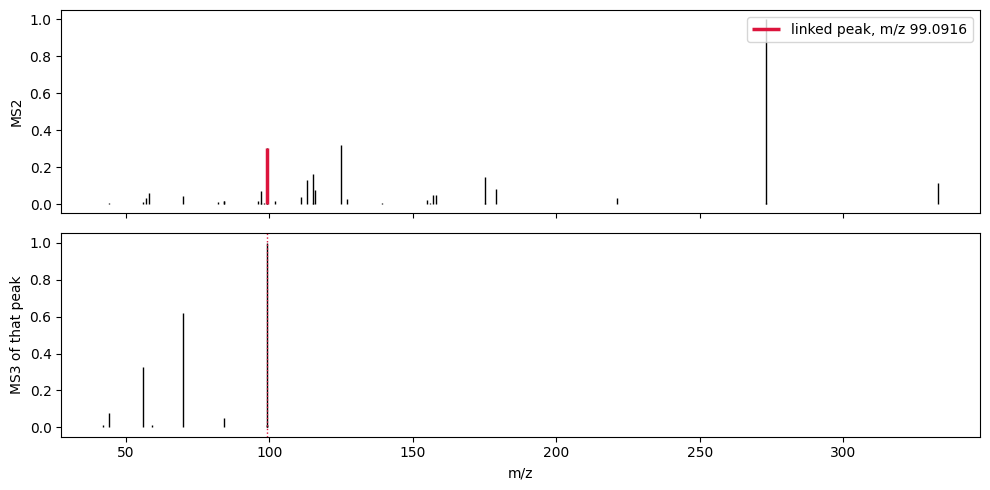

In [4]:
figure, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
top.vlines(ms2.mz, 0, ms2.intensity / ms2.intensity.max(), color="black", linewidth=1)
top.vlines(ms2.mz[peak], 0, ms2.intensity[peak] / ms2.intensity.max(), color="crimson", linewidth=2.5,
           label=f"linked peak, m/z {ms2.mz[peak]:.4f}")
top.set_ylabel("MS2"); top.legend()
bottom.vlines(ms3.mz, 0, ms3.intensity / ms3.intensity.max(), color="black", linewidth=1)
bottom.axvline(ms2.mz[peak], color="crimson", linestyle=":", linewidth=1)
bottom.set_ylabel("MS3 of that peak"); bottom.set_xlabel("m/z")
plt.tight_layout(); plt.show()

## 4. The MAGMa candidates of that peak

In [5]:
plot_fragment_bags(bags[peak])

## 5. Each candidate and its predicted spectrum

The GNN gets each candidate as its input and predicts heights at the MS3's m/z values. The isolated ion's own peak is left out, because every candidate has it.


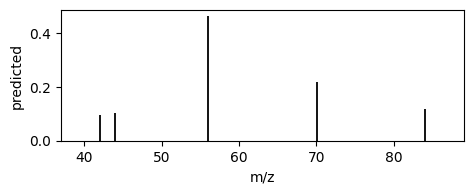
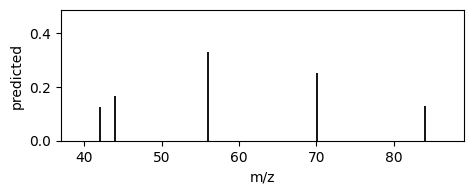
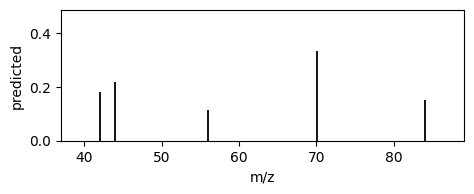

In [6]:
candidates, mz, measured, spectra = candidate_spectra(model, ms2, ms3, peak)
plot_candidate_rows(candidates, mz, spectra)

## 6. Non-negative weights

In [7]:
weights, _ = nnls(spectra.T, measured)     # measured ≈ sum_k weights[k] * spectra[k], weights >= 0
mixed = (weights[:, None] * spectra).sum(0)
print(f"cosine(weighted sum, measured MS3) = {cosine(mixed, measured):.3f}")
scores = weights / weights.sum() if weights.sum() > 0 else weights
plot_candidate_rows(candidates, captions=[f"score {s:.2f}" for s in scores])

cosine(weighted sum, measured MS3) = 0.861


## 7. The weighted sum against the measured MS3

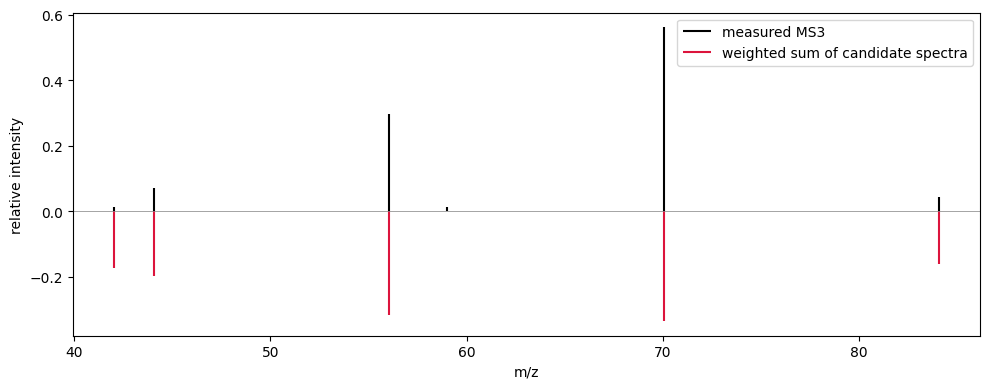

cosine(weighted sum, measured MS3) = 0.861


In [8]:
figure, ax = plt.subplots(figsize=(10, 4))
ax.vlines(mz, 0, measured, color="black", linewidth=1.5, label="measured MS3")
ax.vlines(mz, 0, -mixed, color="crimson", linewidth=1.5, label="weighted sum of candidate spectra")
ax.axhline(0, color="gray", linewidth=0.5)
ax.set_xlabel("m/z"); ax.set_ylabel("relative intensity"); ax.legend()
plt.tight_layout(); plt.show()
print(f"cosine(weighted sum, measured MS3) = {cosine(mixed, measured):.3f}")

## 8. Bond score against MS3 score

How often the fragment with the lowest bond score (the GLACIER / ms-pred heuristic) is the candidate with the highest MS3-derived score, or one of them when several are tied.

In [9]:
from intensity_lab.bond_score_comparison import comparison_table, report, show_example

# all validation molecules (there are fewer than 1000); about 25 minutes the first time, then loaded from disk
table = comparison_table(data, model, molecules=1000)
report(table)

942 molecules, 4,615 MS3-linked MS2 peaks, 3,422 with at least 2 candidates and an MS3 score

Lowest bond score is (among) the highest MS3-scored candidate(s):
  all peaks                          3,422 peaks    39.3%   (chance 24.9%)
  our top is a single candidate      3,265 peaks    38.5%   (chance 23.2%)
  our top is a tie                     157 peaks    54.8%   (chance 59.8%)


## 9. A random peak where they agree

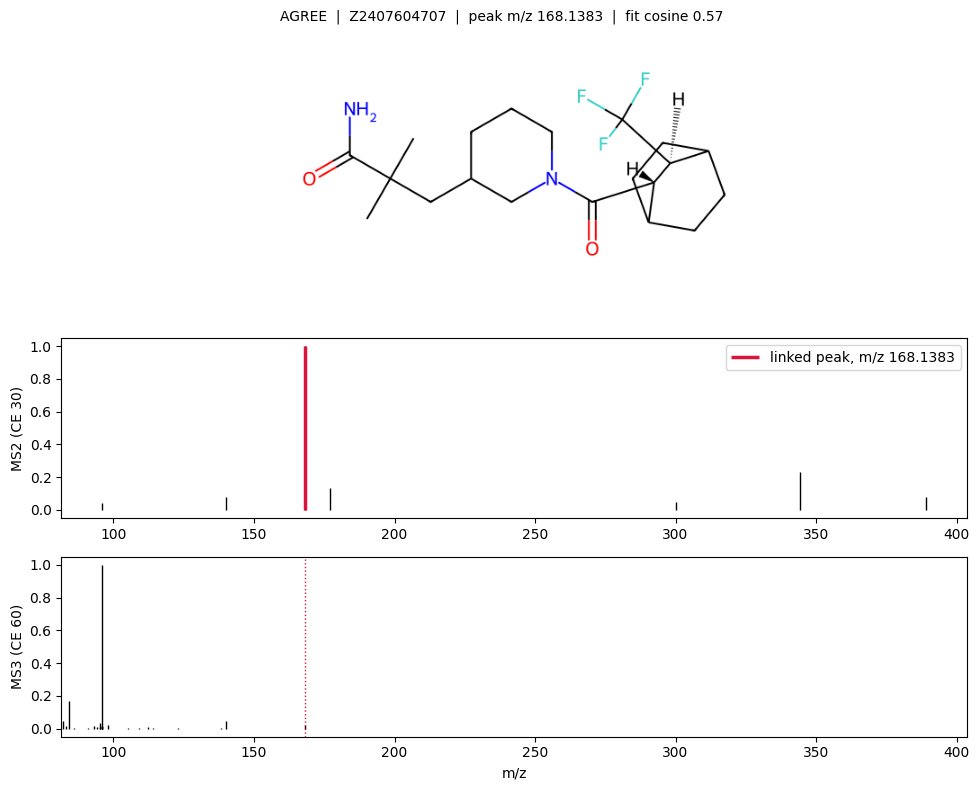

Candidate 1bond score 2 ← lowestMS3 score 0.93 ← highest,,
Candidate 0bond score 4MS3 score 0.07,,
Candidate 2bond score 2 ← lowestMS3 score 0.00,,
Candidate 3bond score 8MS3 score 0.00,,
Candidate 4bond score 5MS3 score 0.00,,
Candidate 5bond score 7MS3 score 0.00,,

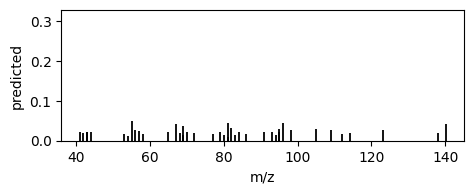
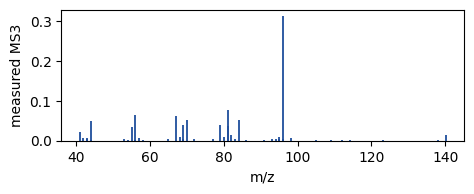
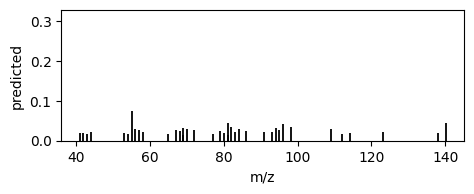
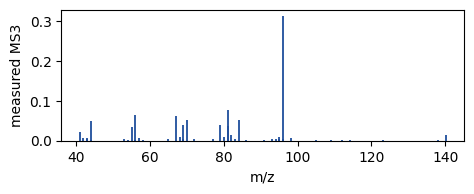
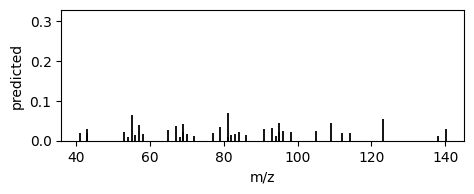
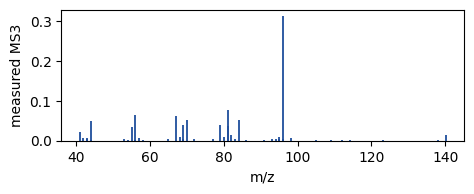
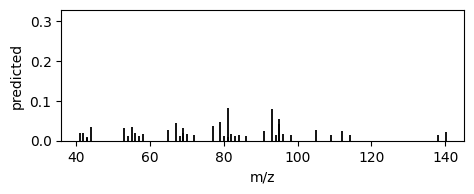
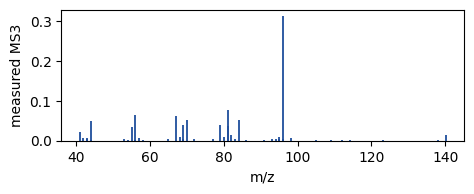
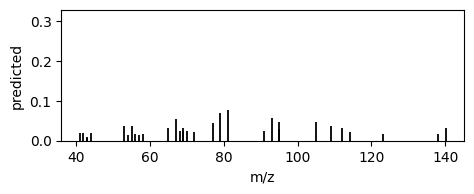
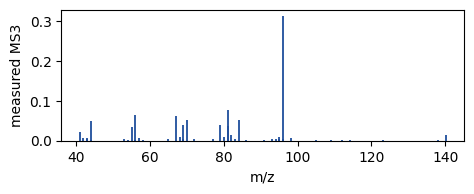
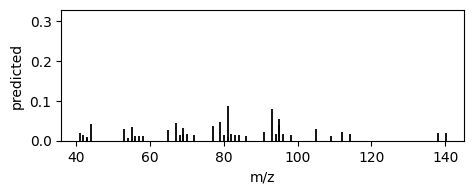
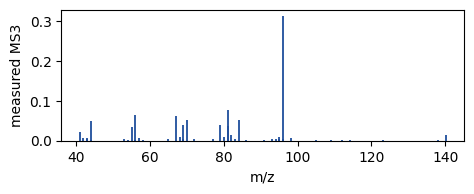

In [10]:
show_example(model, features, table, agree=True, seed=SEED, max_candidates=MAX_CANDIDATES)

## 10. A random peak where they disagree

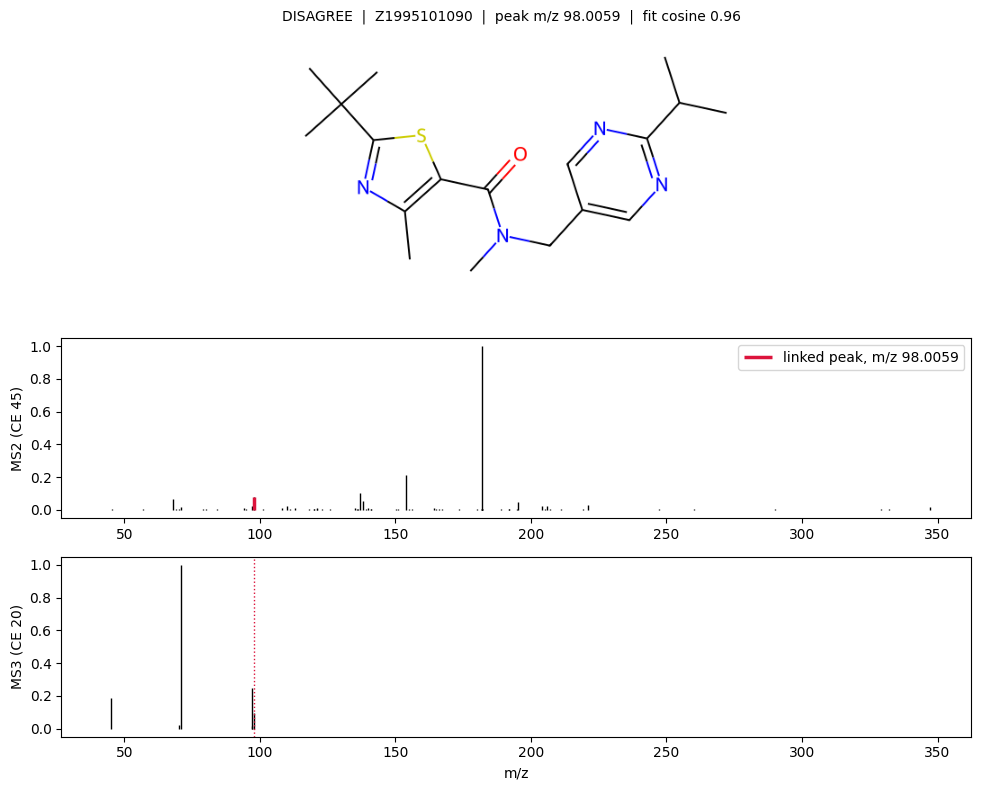


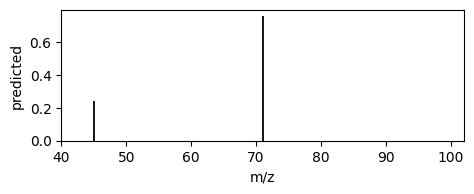
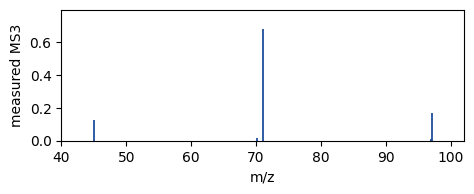
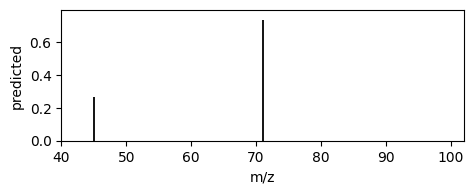
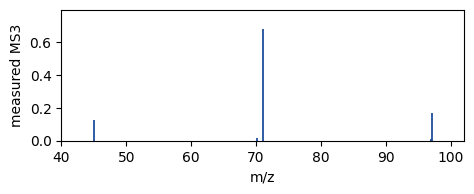
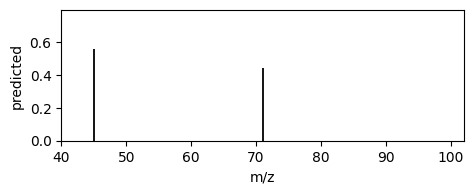
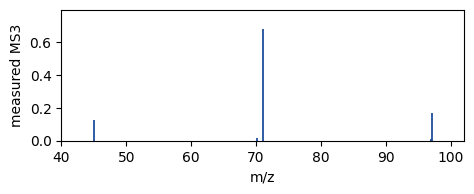

In [11]:
show_example(model, features, table, agree=False, seed=SEED, max_candidates=MAX_CANDIDATES)